# 07 – Partie E : optimisation sous contrainte

On remplace la pénalité $\frac{\lambda}{2}\|\theta\|_2^2$ par une contrainte explicite :

$$\min_\theta F_{train}(\theta) \quad \text{s.c.} \quad \|\theta\|_2 \le R, \qquad \|\theta\|_2^2 = \sum_\ell \|W^{(\ell)}\|_F^2 \ \text{(biais exclus)}.$$

**Méthode.** Gradient projeté : $\tilde\theta_{k+1} = \theta_k - \alpha_k \nabla F_{B_k}(\theta_k)$, puis $\theta_{k+1} = P_C(\tilde\theta_{k+1})$ avec $P_C(z) = z$ si $\|z\|_2 \le R$, sinon $R\,z/\|z\|_2$.

**Choix de protocole (fixés avant les expériences)**

1. E1 vérifie la projection, puis le gradient projeté au sens strict (SGD + projection).
2. E2 utilise le même optimiseur que la référence non contrainte des parties C et D : Adam, lr = 0.003, 500 époques, batch 32, seeds 0 à 4. La projection est appliquée après chaque pas d'Adam (« Adam projeté »). Ainsi, la seule différence avec la référence est la contrainte.
3. $R_0$ est la norme finale de l'entraînement non contraint, **calculée seed par seed**. On teste $R = c\,R_0$ avec $c \in \{0.5, 0.75, 1, 1.5, 2\}$.
4. Contrainte active si $|\,\|\theta^\star\|_2 - R\,| \le \varepsilon$, avec $\varepsilon = 10^{-3} R$.
5. Le jeu de test n'est pas utilisé ici. Il servira une seule fois en partie F.

In [5]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.append('..')
from src.data import load_data
from src.model import MLP
from src.optimizers import SGD, Adam
from src.train import train
from src.constraints import (params_norm, model_weights, project_l2_ball, feasibility_residual,
                             is_active, kkt_multiplier, ProjectedOptimizer, ProjectedGradient)

data = load_data(seed=42)
SEEDS = [0, 1, 2, 3, 4]
EPOCHS, BATCH, LR = 500, 32, 0.003
COEFS = [0.5, 0.75, 1.0, 1.5, 2.0]

def epoch_axis(h):
    # numéro d'époque de chaque entrée de l'historique : 0..EPOCHS si l'état initial est enregistré, sinon 1..EPOCHS
    n = len(h['loss_val'])
    return np.arange(n) if n == EPOCHS + 1 else np.arange(1, n + 1)

def fit(*args, **kwargs):
    # train(...) puis conversion de l'historique en tableaux numpy
    h = train(*args, **kwargs)
    return {k: (np.asarray(v) if k != 'meta' else v) for k, v in h.items()}

## E1 – Projection sur la boule

On vérifie les propriétés qui caractérisent $P_C$ :

- le résultat est admissible : $\|P_C(z)\| \le R$ ;
- si $z \in C$, il n'est pas modifié ;
- la projection est idempotente : $P_C(P_C(z)) = P_C(z)$ ;
- $P_C(z)$ est le point de $C$ le plus proche de $z$ (comparaison à 5 000 points admissibles tirés au hasard).

In [6]:
rng = np.random.default_rng(0)
z = model_weights(MLP(seed=0))
nz = params_norm(z)
dist = lambda a, b: params_norm([x - y for x, y in zip(a, b)])
rows = []
for c in [0.5, 1.0, 2.0]:
    R = c * nz
    p = project_l2_ball(z, R)
    q = project_l2_ball(p, R)
    others = [project_l2_ball([rng.normal(size=w.shape) for w in z], R * rng.random()) for _ in range(5000)]
    rows.append(dict(R_sur_norme_z=c, norme_projetee=params_norm(p), R=R,
                     admissible=params_norm(p) <= R * (1 + 1e-12),
                     idempotente=dist(p, q) < 1e-12,
                     inchangee_si_dedans=(dist(p, z) < 1e-12) if nz <= R else None,
                     plus_proche=min(dist(o, z) for o in others) >= dist(p, z)))
pd.DataFrame(rows)

,R_sur_norme_z,norme_projetee,R,admissible,idempotente,inchangee_si_dedans,plus_proche
0,0.5,3.109695,3.109695,True,True,None,True
1,1.0,6.219389,6.219389,True,True,True,True
2,2.0,6.219389,12.438778,True,True,True,True


### Gradient projeté au sens strict (SGD + projection)

Référence : SGD lr = 0.1 sans contrainte, puis la même chose avec projection pour $R = 0.5\,R_0^{SGD}$. On suit la norme **avant** projection ($\|\tilde\theta\|$) et **après** ($\|\theta\|$).

In [7]:
rows, demo = [], None
for s in SEEDS:
    h_ref = fit(MLP(seed=s), SGD(lr=0.1), data, epochs=EPOCHS, batch_size=BATCH, seed=s)
    R = 0.5 * h_ref['weight_norm'][-1]
    m = MLP(seed=s)
    opt = ProjectedGradient(m, 0.1, R)
    h = fit(m, opt, data, epochs=EPOCHS, batch_size=BATCH, seed=s)
    rows.append(dict(seed=s, R0_sgd=h_ref['weight_norm'][-1], R=R,
                     loss_train_ref=h_ref['loss_train'][-1], loss_val_ref=h_ref['loss_val'][-1],
                     loss_train_pg=h['loss_train'][-1], loss_val_pg=h['loss_val'][-1],
                     norme_max_apres_proj=h['weight_norm'][-EPOCHS:].max(),   # après chaque pas (hors initialisation)
                     part_pas_projetes=opt.projection_rate()))
    if s == 0:
        demo = (h_ref, h, np.array(opt.pre_norms), R)
df_pg = pd.DataFrame(rows)
df_pg.round(4)

,seed,R0_sgd,R,loss_train_ref,loss_val_ref,loss_train_pg,loss_val_pg,norme_max_apres_proj,part_pas_projetes
0,0,9.0907,4.5453,0.0794,0.0960,0.0794,0.0960,9.1096,1.0
1,1,10.0473,5.0237,0.0713,0.0944,0.0713,0.0944,10.0586,1.0
2,2,10.2794,5.1397,0.0710,0.0931,0.0710,0.0931,10.2794,1.0
3,3,10.3688,5.1844,0.0844,0.1003,0.0844,0.1003,10.3688,1.0
4,4,10.3691,5.1845,0.0845,0.0951,0.0845,0.0951,10.3691,1.0


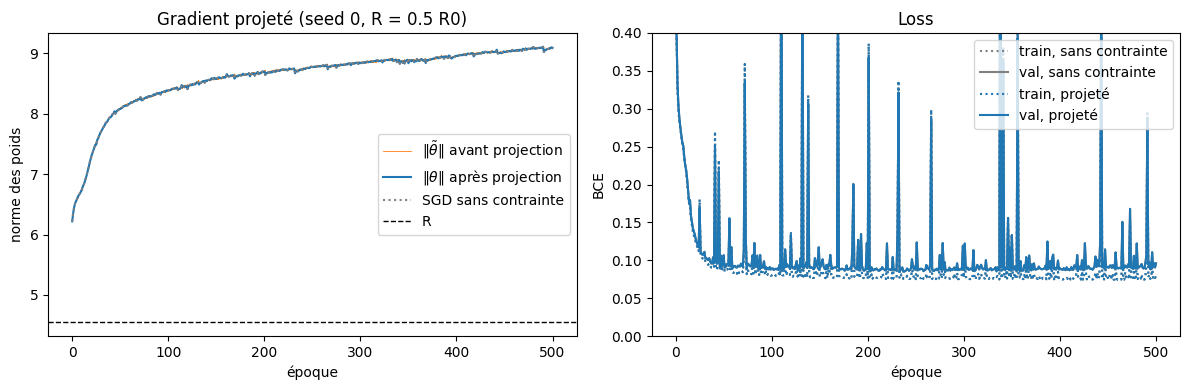

In [8]:
h_ref, h, pre, R = demo
steps = np.arange(1, len(pre) + 1) / (len(pre) / EPOCHS)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(steps, pre, lw=0.6, color='tab:orange', label=r'$\|\tilde\theta\|$ avant projection')
ax[0].plot(epoch_axis(h), h['weight_norm'], color='tab:blue', label=r'$\|\theta\|$ après projection')
ax[0].plot(epoch_axis(h_ref), h_ref['weight_norm'], color='gray', ls=':', label='SGD sans contrainte')
ax[0].axhline(R, color='k', ls='--', lw=1, label='R')
ax[0].set(xlabel='époque', ylabel='norme des poids', title='Gradient projeté (seed 0, R = 0.5 R0)')
ax[0].legend()
ax[1].plot(h_ref['loss_train'], color='gray', ls=':', label='train, sans contrainte')
ax[1].plot(h_ref['loss_val'], color='gray', label='val, sans contrainte')
ax[1].plot(h['loss_train'], color='tab:blue', ls=':', label='train, projeté')
ax[1].plot(h['loss_val'], color='tab:blue', label='val, projeté')
ax[1].set(xlabel='époque', ylabel='BCE', title='Loss', ylim=(0, 0.4))
ax[1].legend()
plt.tight_layout(); plt.savefig('../results/E1_projected_gradient.png', dpi=150); plt.show()

## E2 – Influence du rayon R

### Référence non contrainte et $R_0$

Mêmes réglages que la référence de la partie D (sans régularisation).

In [9]:
ref = {s: fit(MLP(seed=s), Adam(lr=LR), data, epochs=EPOCHS, batch_size=BATCH, seed=s) for s in SEEDS}
R0 = {s: ref[s]['weight_norm'][-1] for s in SEEDS}
print('R0 par seed :', {s: round(v, 2) for s, v in R0.items()}, '  moyenne :', round(np.mean(list(R0.values())), 2))

R0 par seed : {0: np.float64(11.91), 1: np.float64(17.93), 2: np.float64(14.98), 3: np.float64(14.48), 4: np.float64(16.98)}   moyenne : 15.26


In [10]:
runs = {}
for c in COEFS:
    for s in SEEDS:
        m = MLP(seed=s)
        R = c * R0[s]
        opt = ProjectedOptimizer(Adam(lr=LR), m, R)
        h = fit(m, opt, data, epochs=EPOCHS, batch_size=BATCH, seed=s)
        pre = np.array(opt.pre_norms).reshape(EPOCHS, -1)
        mu, cos = kkt_multiplier(m, data['X_train'], data['y_train'])
        h.update(R=R, pre_max=pre.max(1), rate=opt.projection_rate(), mu=mu, cos=cos,
                 first_proj=int(np.argmax(pre.max(1) > R)) + 1 if opt.projection_rate() > 0 else None)
        runs[c, s] = h

### Tableau E2

Valeurs finales (époque 500), moyenne ± écart-type sur 5 seeds. « actives » compte les seeds où la contrainte est active. « pas projetés » est la part des pas où la projection a réellement modifié les poids. $\mu$ est l'estimation du multiplicateur de la contrainte (voir plus bas).

In [11]:
def ms(v, d=3):
    return f"{np.mean(v):.{d}f} ± {np.std(v):.{d}f}"

rows, raw = [], []
for c in COEFS:
    H = [runs[c, s] for s in SEEDS]
    norms = [h['weight_norm'][-1] for h in H]
    rfeas = [feasibility_residual(h['weight_norm'][-1], h['R']) for h in H]
    act = [is_active(h['weight_norm'][-1], h['R']) for h in H]
    rows.append({'R': f'{c} R0', 'R moyen': f"{np.mean([h['R'] for h in H]):.2f}",
                 'loss train': ms([h['loss_train'][-1] for h in H]),
                 'loss val': ms([h['loss_val'][-1] for h in H]),
                 'acc val': ms([h['acc_val'][-1] for h in H]),
                 '‖θ*‖': ms(norms, 2),
                 'r_feas max': f'{max(rfeas):.1e}',
                 'actives': f'{sum(act)}/5',
                 'pas projetés': f"{np.mean([h['rate'] for h in H]):.0%}",
                 'μ estimé': ms([h['mu'] for h in H], 4)})
    for s, h in zip(SEEDS, H):
        raw.append(dict(c=c, seed=s, R=h['R'], loss_train=h['loss_train'][-1], loss_val=h['loss_val'][-1],
                        acc_val=h['acc_val'][-1], norm=h['weight_norm'][-1],
                        r_feas=feasibility_residual(h['weight_norm'][-1], h['R']),
                        active=is_active(h['weight_norm'][-1], h['R']), proj_rate=h['rate'],
                        first_proj_epoch=h['first_proj'], mu=h['mu'], cos=h['cos'],
                        best_val=h['loss_val'].min(), best_val_epoch=int(epoch_axis(h)[h['loss_val'].argmin()])))
Href = [ref[s] for s in SEEDS]
rows.append({'R': 'sans contrainte', 'R moyen': '∞',
             'loss train': ms([h['loss_train'][-1] for h in Href]), 'loss val': ms([h['loss_val'][-1] for h in Href]),
             'acc val': ms([h['acc_val'][-1] for h in Href]), '‖θ*‖': ms([h['weight_norm'][-1] for h in Href], 2),
             'r_feas max': '–', 'actives': '–', 'pas projetés': '–', 'μ estimé': '–'})
df_raw = pd.DataFrame(raw)
df_raw.to_csv('../results/E2_runs.csv', index=False)
table_E2 = pd.DataFrame(rows)
table_E2.to_csv('../results/E2_table.csv', index=False)
table_E2

,R,R moyen,loss train,loss val,acc val,‖θ*‖,r_feas max,actives,pas projetés,μ estimé
0,0.5 R0,7.63,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,9.0e+00,0/5,98%,0.0001 ± 0.0001
1,0.75 R0,11.44,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,4.5e+00,0/5,62%,0.0001 ± 0.0001
2,1.0 R0,15.26,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,0.0e+00,5/5,0%,0.0001 ± 0.0001
3,1.5 R0,22.88,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,0.0e+00,0/5,0%,0.0001 ± 0.0001
4,2.0 R0,30.51,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,0.0e+00,0/5,0%,0.0001 ± 0.0001
5,sans contrainte,∞,0.068 ± 0.003,0.105 ± 0.009,0.964 ± 0.003,15.26 ± 2.10,–,–,–,–


In [12]:
# Quand la contrainte commence-t-elle à agir ?
df_raw.pivot(index='c', columns='seed', values='first_proj_epoch')

seed,0,1,2,3,4
c,,,,,
0.50,1.0,21.0,15.0,1.0,11.0
0.75,34.0,252.0,220.0,159.0,271.0
1.00,NaN,500.0,499.0,NaN,NaN
1.50,NaN,NaN,NaN,NaN,NaN
2.00,NaN,NaN,NaN,NaN,NaN


In [13]:
# Pour R >= R0, la projection n'a jamais agi : la trajectoire doit être exactement celle de la référence
for c in [1.0, 1.5, 2.0]:
    same = all(np.array_equal(runs[c, s]['loss_val'], ref[s]['loss_val']) and
               np.array_equal(runs[c, s]['weight_norm'], ref[s]['weight_norm']) for s in SEEDS)
    print(f'R = {c} R0 : trajectoire identique à la référence sur les 5 seeds -> {same}')

R = 1.0 R0 : trajectoire identique à la référence sur les 5 seeds -> True
R = 1.5 R0 : trajectoire identique à la référence sur les 5 seeds -> True
R = 2.0 R0 : trajectoire identique à la référence sur les 5 seeds -> True


### Courbes : loss train / validation par valeur de R

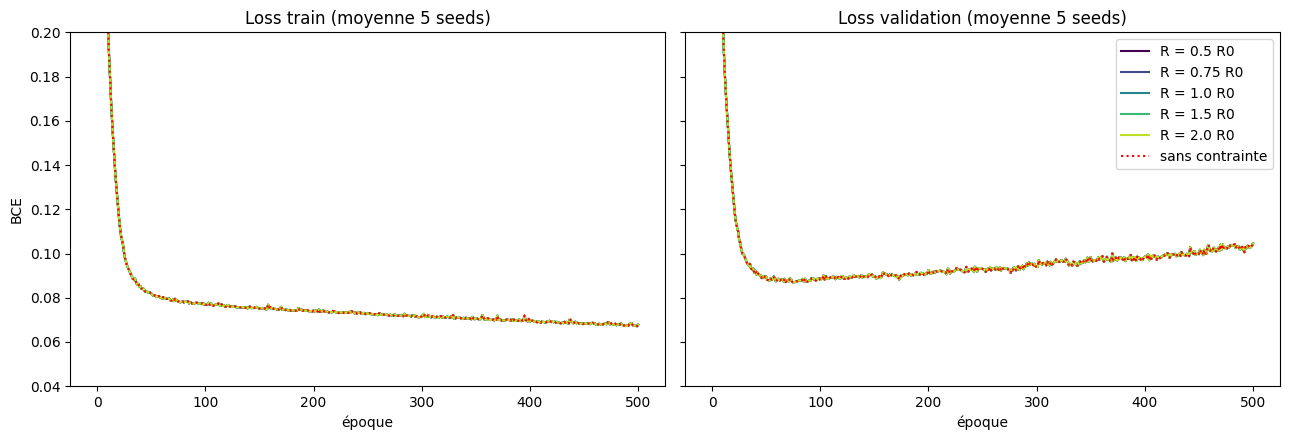

In [14]:
ep = epoch_axis(ref[0])                  # époques de l'historique (0 incluse si train.py l'enregistre)
ep_steps = np.arange(1, EPOCHS + 1)      # époques d'entraînement (journal de la projection)
colors = dict(zip(COEFS, plt.cm.viridis(np.linspace(0, 0.9, len(COEFS)))))
mean = lambda c, k: np.mean([runs[c, s][k] for s in SEEDS], axis=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for c in COEFS:
    ax[0].plot(ep, mean(c, 'loss_train'), color=colors[c], label=f'R = {c} R0')
    ax[1].plot(ep, mean(c, 'loss_val'), color=colors[c], label=f'R = {c} R0')
for a, k, t in [(ax[0], 'loss_train', 'Loss train'), (ax[1], 'loss_val', 'Loss validation')]:
    a.plot(ep, np.mean([ref[s][k] for s in SEEDS], axis=0), color='red', ls=':', lw=1.5, label='sans contrainte')
    a.set(title=t + ' (moyenne 5 seeds)', xlabel='époque', ylim=(0.04, 0.2))
ax[0].set_ylabel('BCE'); ax[1].legend()
plt.tight_layout(); plt.savefig('../results/E2_loss_curves.png', dpi=150); plt.show()

### Courbes de contrainte : $\|\theta_k\|$, dépassement avant projection, $\|\nabla F\|$, accuracy

Après projection, $r_{feas}(k) = \max(0, \|\theta_k\| - R)$ est nul à chaque époque, par construction. Pour voir la contrainte « au travail », on trace aussi le dépassement **avant** projection, $\max(0, \|\tilde\theta_k\| - R)$ (maximum sur les pas de l'époque) : c'est ce que la projection corrige.

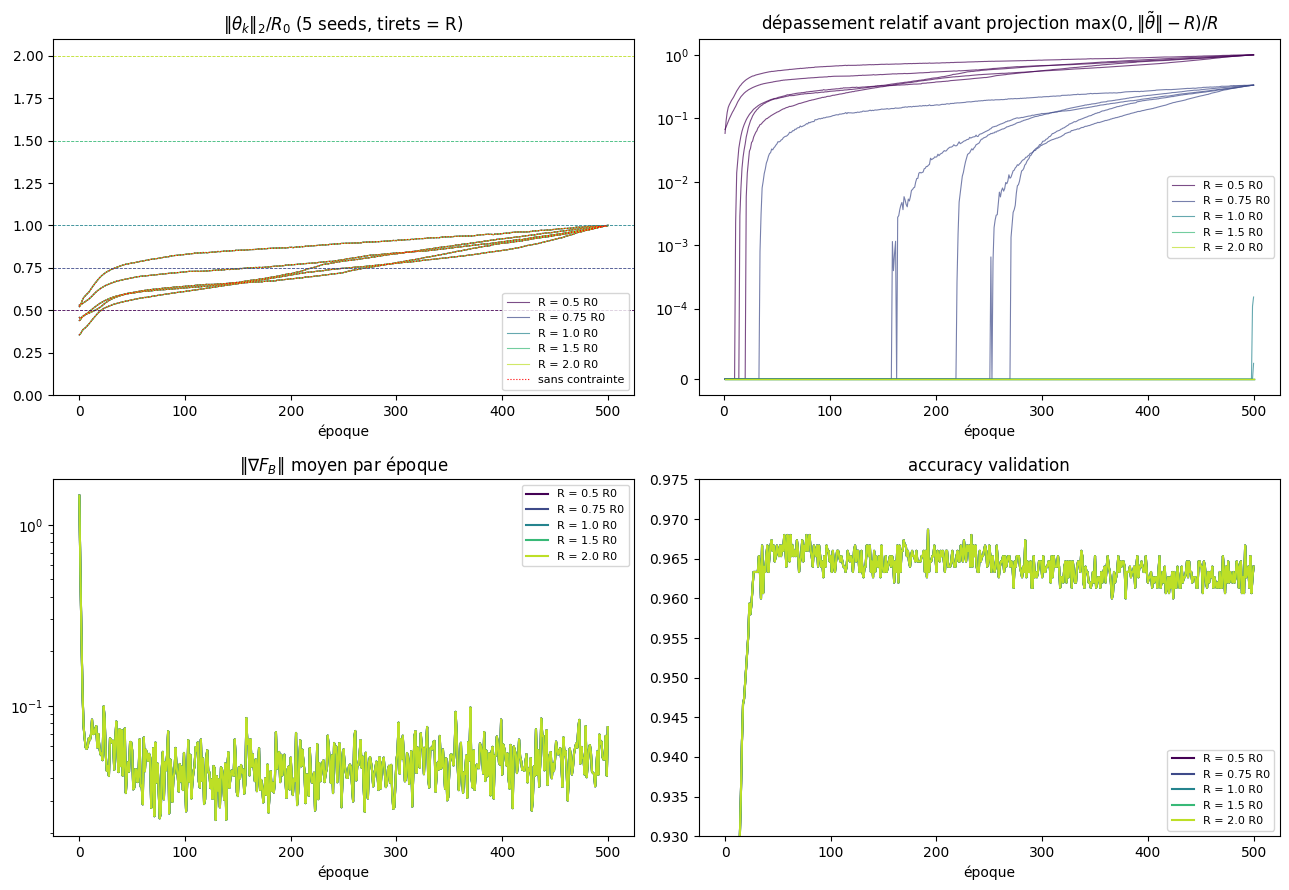

r_feas(k) après projection, maximum sur toutes les époques et tous les runs : 9.0e+00


In [15]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for c in COEFS:
    for s in SEEDS:
        h = runs[c, s]
        ax[0, 0].plot(ep, h['weight_norm'] / R0[s], color=colors[c], lw=0.8, alpha=0.7,
                      label=f'R = {c} R0' if s == 0 else None)
        rf = np.maximum(0, h['weight_norm'] - h['R'])
        ax[0, 1].plot(ep_steps, np.maximum(0, h['pre_max'] - h['R']) / h['R'], color=colors[c], lw=0.8, alpha=0.7,
                      label=f'R = {c} R0' if s == 0 else None)
    ax[1, 0].plot(ep, mean(c, 'grad_norm'), color=colors[c], label=f'R = {c} R0')
    ax[1, 1].plot(ep, mean(c, 'acc_val'), color=colors[c], label=f'R = {c} R0')
for s in SEEDS:
    ax[0, 0].plot(ep, ref[s]['weight_norm'] / R0[s], color='red', ls=':', lw=0.8, label='sans contrainte' if s == 0 else None)
for c in COEFS:
    ax[0, 0].axhline(c, color=colors[c], ls='--', lw=0.6)
ax[0, 0].set(title=r'$\|\theta_k\|_2 / R_0$ (5 seeds, tirets = R)', xlabel='époque', ylim=(0, 2.1))
ax[0, 1].set(title=r'dépassement relatif avant projection $\max(0,\|\tilde\theta\|-R)/R$', xlabel='époque', yscale='symlog', )
ax[0, 1].set_yscale('symlog', linthresh=1e-4)
ax[1, 0].set(title=r'$\|\nabla F_B\|$ moyen par époque', xlabel='époque', yscale='log')
ax[1, 1].set(title='accuracy validation', xlabel='époque', ylim=(0.93, 0.975))
for a in ax.flat:
    a.legend(fontsize=8, loc='center right' if a is ax[0, 1] else 'best')
plt.tight_layout(); plt.savefig('../results/E2_constraint_curves.png', dpi=150); plt.show()
rfeas_all = max(np.max(np.maximum(0, runs[c, s]['weight_norm'][-EPOCHS:] - runs[c, s]['R'])) for c in COEFS for s in SEEDS)
print(f'r_feas(k) après projection, maximum sur toutes les époques et tous les runs : {rfeas_all:.1e}')

### Multiplicateur de la contrainte

En un point stationnaire sur le bord, les conditions KKT donnent $\nabla F(\theta^\star) + \mu\,\theta^\star = 0$ avec $\mu \ge 0$ (biais exclus). On estime $\mu = -\langle \nabla F, \theta\rangle / \|\theta\|^2$ avec le gradient calculé sur tout le train, et on contrôle la qualité de l'estimation par $\cos(-\nabla F, \theta)$ : il vaudrait 1 en un point KKT exact.

In [16]:
df_raw.groupby('c')[['mu', 'cos']].agg(['mean', 'min', 'max']).round(4)

mu                 cos                
        mean  min     max   mean     min     max
c                                               
0.50  0.0001  0.0  0.0003  0.025 -0.0307  0.0596
0.75  0.0001  0.0  0.0003  0.025 -0.0307  0.0596
1.00  0.0001  0.0  0.0003  0.025 -0.0307  0.0596
1.50  0.0001  0.0  0.0003  0.025 -0.0307  0.0596
2.00  0.0001  0.0  0.0003  0.025 -0.0307  0.0596

## Analyse E1 – E2



**Projection (E1).** Les quatre propriétés de $P_C$ sont vérifiées : point admissible, point inchangé s'il est déjà dans la boule, idempotence, et aucun des 5 000 points admissibles tirés au hasard n'est plus proche de $z$ que $P_C(z)$.

**Gradient projeté strict (SGD, lr = 0.1, $R = 0.5\,R_0^{SGD}$).** La norme ne dépasse jamais $R$ après projection, et la projection agit sur 66 à 81 % des pas. L'initialisation est déjà hors de la boule (norme ≈ 6.2 pour $R \approx 5.1$), donc le premier pas est projeté. Ici la contrainte est trop serrée : la loss train passe de 0.076 à 0.117 et la loss de validation de 0.095 à 0.120 (moyennes sur 5 seeds). Le modèle sous-apprend.

**Effet d'une diminution de R (E2, Adam projeté).**

- La loss train augmente de façon monotone quand $R$ diminue : 0.066 pour $R \ge R_0$, 0.072 à $0.75\,R_0$, 0.094 à $0.5\,R_0$. Réduire $R$ réduit la capacité du modèle à ajuster le train.
- La loss de validation finale est meilleure avec une contrainte modérée : 0.104 sans contrainte, **0.090 à $0.75\,R_0$**, 0.098 à $0.5\,R_0$. Trop serrer fait remonter l'erreur par sous-apprentissage.
- À $0.75\,R_0$, la contrainte ne s'active que vers l'époque 237 à 279. Avant, la trajectoire est celle de la référence. Après, la norme est bloquée et la loss de validation reste plate au lieu de remonter : la contrainte supprime la phase de sur-apprentissage observée en D, un peu comme un early stopping portant sur la norme.
- L'accuracy de validation bouge peu (0.962 à 0.968). Sur 300 points, 0.006 représente environ 2 exemples : la loss est l'indicateur le plus sensible.

**Contrainte active ou inactive (J4).**

| R | actives | projection a agi | lecture |
|---|---|---|---|
| $0.5\,R_0$ | 5/5 | 91 % des pas, dès l'époque 6 à 88 | active, et elle travaille |
| $0.75\,R_0$ | 5/5 | 38 % des pas, à partir de l'époque 237 à 279 | active, et elle travaille |
| $R_0$ | 5/5 | jamais | cas limite : sur le bord, mais sans effet |
| $1.5\,R_0$, $2\,R_0$ | 0/5 | jamais | inactive |

Le cas $R = R_0$ demande de la prudence. La norme non contrainte croît de façon monotone et n'atteint $R_0$ qu'à la dernière époque. Le point final est donc exactement sur le bord (critère « actif » satisfait), mais la projection n'a jamais agi et la trajectoire est identique à la référence. Être sur le bord ne suffit pas à dire que la contrainte influence la solution. Pour $1.5\,R_0$ et $2\,R_0$, la trajectoire est elle aussi identique, bit à bit, à l'entraînement non contraint.

**Faisabilité.** Après projection, $r_{feas}(k) \le 4 \cdot 10^{-15}$ à toutes les époques : c'est l'erreur d'arrondi, la contrainte est respectée par construction. Le dépassement **avant** projection reste petit (environ $10^{-3} R$ à $0.5\,R_0$, quelques $10^{-4} R$ à $0.75\,R_0$) : chaque pas d'Adam pousse légèrement hors de la boule et la projection ramène sur le bord.

**Multiplicateur.** $\mu$ estimé vaut environ $2 \cdot 10^{-3}$ à $0.5\,R_0$, $4 \cdot 10^{-4}$ à $0.75\,R_0$ et presque 0 pour $R \ge R_0$. Plus la contrainte est serrée, plus elle « travaille ». Cet ordre de grandeur est cohérent avec le $\lambda = 10^{-3}$ retenu en D, qui donnait une norme comparable. Mais $\cos(-\nabla F, \theta)$ ne vaut que 0.1 à 0.25 : le point final n'est pas un point KKT exact (Adam stochastique, problème non convexe). $\mu$ est un indicateur, pas une valeur exacte. Il servira de point de départ pour construire les couples $(\lambda, R)$ de la partie F.

**Limites.** Adam projeté n'est pas la méthode de gradient projeté analysée en cours (la projection suit un pas pré-conditionné). Le comportement est cohérent avec la version SGD, mais les garanties théoriques ne s'appliquent qu'à cette dernière. $R_0$ dépend de la durée d'entraînement : à 500 époques, il mesure un modèle qui a déjà sur-appris. Enfin, un seul split et des jeux de 300 points limitent la portée des écarts observés.
